In [1]:
import random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import OxfordIIITPet
import torchvision.transforms.functional as TF

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print("Using device:", device)

IMG_SIZE    = 128     # train at 128x128 (fast, still clear enough)
BATCH_SIZE  = 16
EPOCHS      = 15
LR          = 1e-3
NUM_WORKERS = 2 if device == "cuda" else 0   # set 0 if you hit DataLoader errors on Windows/macOS

Using device: cuda


In [2]:
trainval_raw = OxfordIIITPet(root="./data", split="trainval", target_types="segmentation", download=True)
test_raw     = OxfordIIITPet(root="./data", split="test",     target_types="segmentation", download=True)
print(f"trainval: {len(trainval_raw):,} images | test: {len(test_raw):,} images")

100%|██████████| 792M/792M [00:44<00:00, 18.0MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.38MB/s]


trainval: 3,680 images | test: 3,669 images


Image size: (375, 500) | trimap values: [1 2 3]


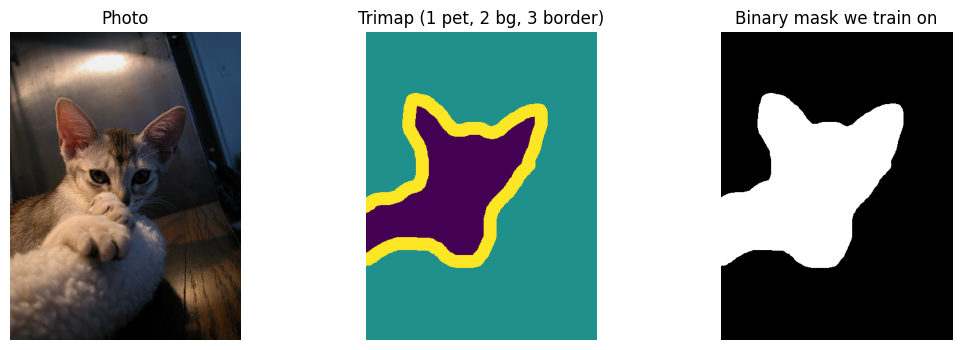

In [3]:
img, trimap = trainval_raw[10]
tri = np.array(trimap)
print("Image size:", img.size, "| trimap values:", np.unique(tri))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img); axes[0].set_title("Photo")
axes[1].imshow(tri, cmap="viridis"); axes[1].set_title("Trimap (1 pet, 2 bg, 3 border)")
axes[2].imshow((tri == 1) | (tri == 3), cmap="gray"); axes[2].set_title("Binary mask we train on")
for a in axes: a.axis("off")
plt.show()

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class PetSegmentation(Dataset):
    def __init__(self, base, augment=False):
        self.base, self.augment = base, augment

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        img, trimap = self.base[i]
        img    = TF.resize(img,    [IMG_SIZE, IMG_SIZE], interpolation=TF.InterpolationMode.BILINEAR)
        trimap = TF.resize(trimap, [IMG_SIZE, IMG_SIZE], interpolation=TF.InterpolationMode.NEAREST)
        if self.augment:
            if random.random() < 0.5:                      # same flip for both
                img, trimap = TF.hflip(img), TF.hflip(trimap)
            img = TF.adjust_brightness(img, random.uniform(0.8, 1.2))   # image only
        x = TF.normalize(TF.to_tensor(img), MEAN, STD)
        t = torch.from_numpy(np.array(trimap))
        mask = ((t == 1) | (t == 3)).float().unsqueeze(0)   # (1, H, W): 1 = pet
        return x, mask

idx = torch.randperm(len(trainval_raw), generator=torch.Generator().manual_seed(SEED)).tolist()
n_val = len(idx) // 10
train_ds = Subset(PetSegmentation(trainval_raw, augment=True),  idx[n_val:])
val_ds   = Subset(PetSegmentation(trainval_raw, augment=False), idx[:n_val])
test_ds  = PetSegmentation(test_raw, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

train 3312 | val 368 | test 3669


In [5]:
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8
        self.pool = nn.MaxPool2d(2)
        # Encoder
        self.enc1, self.enc2 = DoubleConv(in_ch, c1), DoubleConv(c1, c2)
        self.enc3, self.enc4 = DoubleConv(c2, c3),    DoubleConv(c3, c4)
        self.bottleneck = DoubleConv(c4, c4 * 2)
        # Decoder: upsample, concatenate the skip, then convolve
        self.up4, self.dec4 = nn.ConvTranspose2d(c4 * 2, c4, 2, stride=2), DoubleConv(c4 * 2, c4)
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2),     DoubleConv(c3 * 2, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2),     DoubleConv(c2 * 2, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2),     DoubleConv(c1 * 2, c1)
        self.head = nn.Conv2d(c1, out_ch, 1)        # one logit per pixel

    def forward(self, x):
        s1 = self.enc1(x)                  # 128
        s2 = self.enc2(self.pool(s1))      # 64
        s3 = self.enc3(self.pool(s2))      # 32
        s4 = self.enc4(self.pool(s3))      # 16
        b  = self.bottleneck(self.pool(s4))  # 8
        d4 = self.dec4(torch.cat([self.up4(b),  s4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), s3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), s2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), s1], dim=1))
        return self.head(d1)

model = UNet().to(device)
with torch.no_grad():
    print("Output shape:", tuple(model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=device)).shape))
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Output shape: (2, 1, 128, 128)
Parameters: 7,763,041


In [6]:
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(1, 2, 3))
    total = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()

bce = nn.BCEWithLogitsLoss()
def seg_loss(logits, target):
    return bce(logits, target) + dice_loss(logits, target)

@torch.no_grad()
def iou_per_image(logits, target, thr=0.5):
    pred = (torch.sigmoid(logits) > thr).float()
    inter = (pred * target).sum(dim=(1, 2, 3))
    union = ((pred + target) > 0).float().sum(dim=(1, 2, 3))
    return (inter + 1e-6) / (union + 1e-6)

In [7]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def evaluate(loader):
    model.eval()
    losses, ious = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            losses.append(seg_loss(logits, y).item())
            ious.append(iou_per_image(logits, y).cpu())
    return float(np.mean(losses)), torch.cat(ious).mean().item()

history = {"train_loss": [], "val_loss": [], "val_iou": []}
best_iou = 0.0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    running = []
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = seg_loss(model(x), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running.append(loss.item())
    scheduler.step()

    val_loss, val_iou = evaluate(val_loader)
    history["train_loss"].append(np.mean(running))
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), "unet_pets_best.pt")
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {np.mean(running):.3f} | val loss {val_loss:.3f} "
          f"| val IoU {val_iou:.3f} {'*' if val_iou == best_iou else ''} | {time.time() - t0:.0f}s")

model.load_state_dict(torch.load("unet_pets_best.pt", map_location=device))
print(f"Best validation IoU: {best_iou:.3f}")

Epoch  1/15 | train loss 0.779 | val loss 0.634 | val IoU 0.681 * | 23s
Epoch  2/15 | train loss 0.599 | val loss 0.560 | val IoU 0.712 * | 23s
Epoch  3/15 | train loss 0.531 | val loss 0.486 | val IoU 0.750 * | 22s
Epoch  4/15 | train loss 0.481 | val loss 0.457 | val IoU 0.773 * | 23s
Epoch  5/15 | train loss 0.431 | val loss 0.411 | val IoU 0.786 * | 23s
Epoch  6/15 | train loss 0.403 | val loss 0.393 | val IoU 0.795 * | 24s
Epoch  7/15 | train loss 0.373 | val loss 0.387 | val IoU 0.799 * | 24s
Epoch  8/15 | train loss 0.345 | val loss 0.343 | val IoU 0.816 * | 23s
Epoch  9/15 | train loss 0.324 | val loss 0.330 | val IoU 0.826 * | 24s
Epoch 10/15 | train loss 0.306 | val loss 0.310 | val IoU 0.832 * | 24s
Epoch 11/15 | train loss 0.287 | val loss 0.304 | val IoU 0.836 * | 23s
Epoch 12/15 | train loss 0.272 | val loss 0.299 | val IoU 0.836 * | 24s
Epoch 13/15 | train loss 0.257 | val loss 0.290 | val IoU 0.842 * | 24s
Epoch 14/15 | train loss 0.248 | val loss 0.286 | val IoU 0.847 

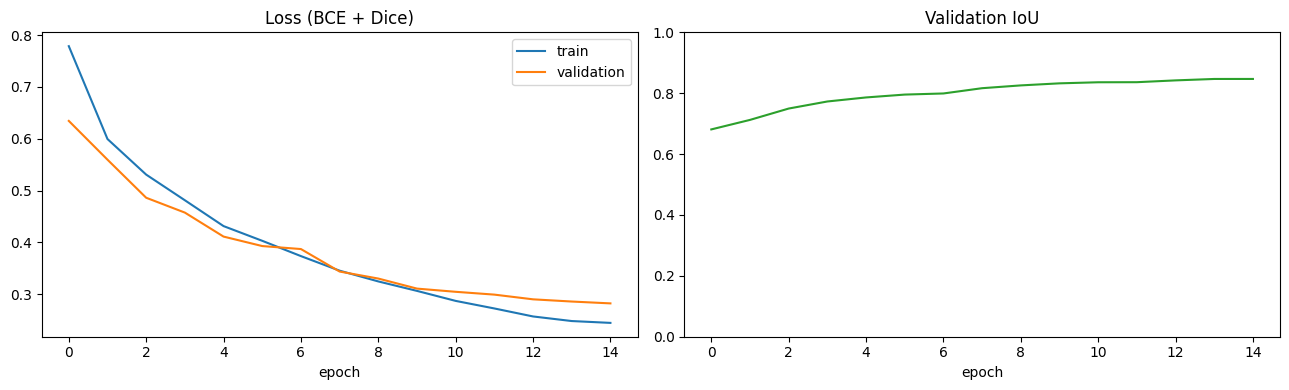

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="validation")
axes[0].set_title("Loss (BCE + Dice)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history["val_iou"], color="tab:green")
axes[1].set_title("Validation IoU"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 8. Test-set results

To put the score in context, compare it with a **trivial baseline** that predicts "the whole image is pet". Pets fill a large part of most photos, so this baseline scores higher than you might expect. The U-Net should clearly beat it.

In [9]:
model.eval()
test_ious, baseline_ious = [], []
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        test_ious.append(iou_per_image(model(x), y).cpu())
        baseline_ious.append(iou_per_image(torch.full_like(y, 10.0), y).cpu())   # predict all-pet
test_ious, baseline_ious = torch.cat(test_ious), torch.cat(baseline_ious)

print(f"U-Net test IoU:           {test_ious.mean():.3f}")
print(f"'Everything is pet' IoU:  {baseline_ious.mean():.3f}")
print(f"Share of test images with IoU > 0.8: {(test_ious > 0.8).float().mean():.0%}")

U-Net test IoU:           0.851
'Everything is pet' IoU:  0.423
Share of test images with IoU > 0.8: 79%


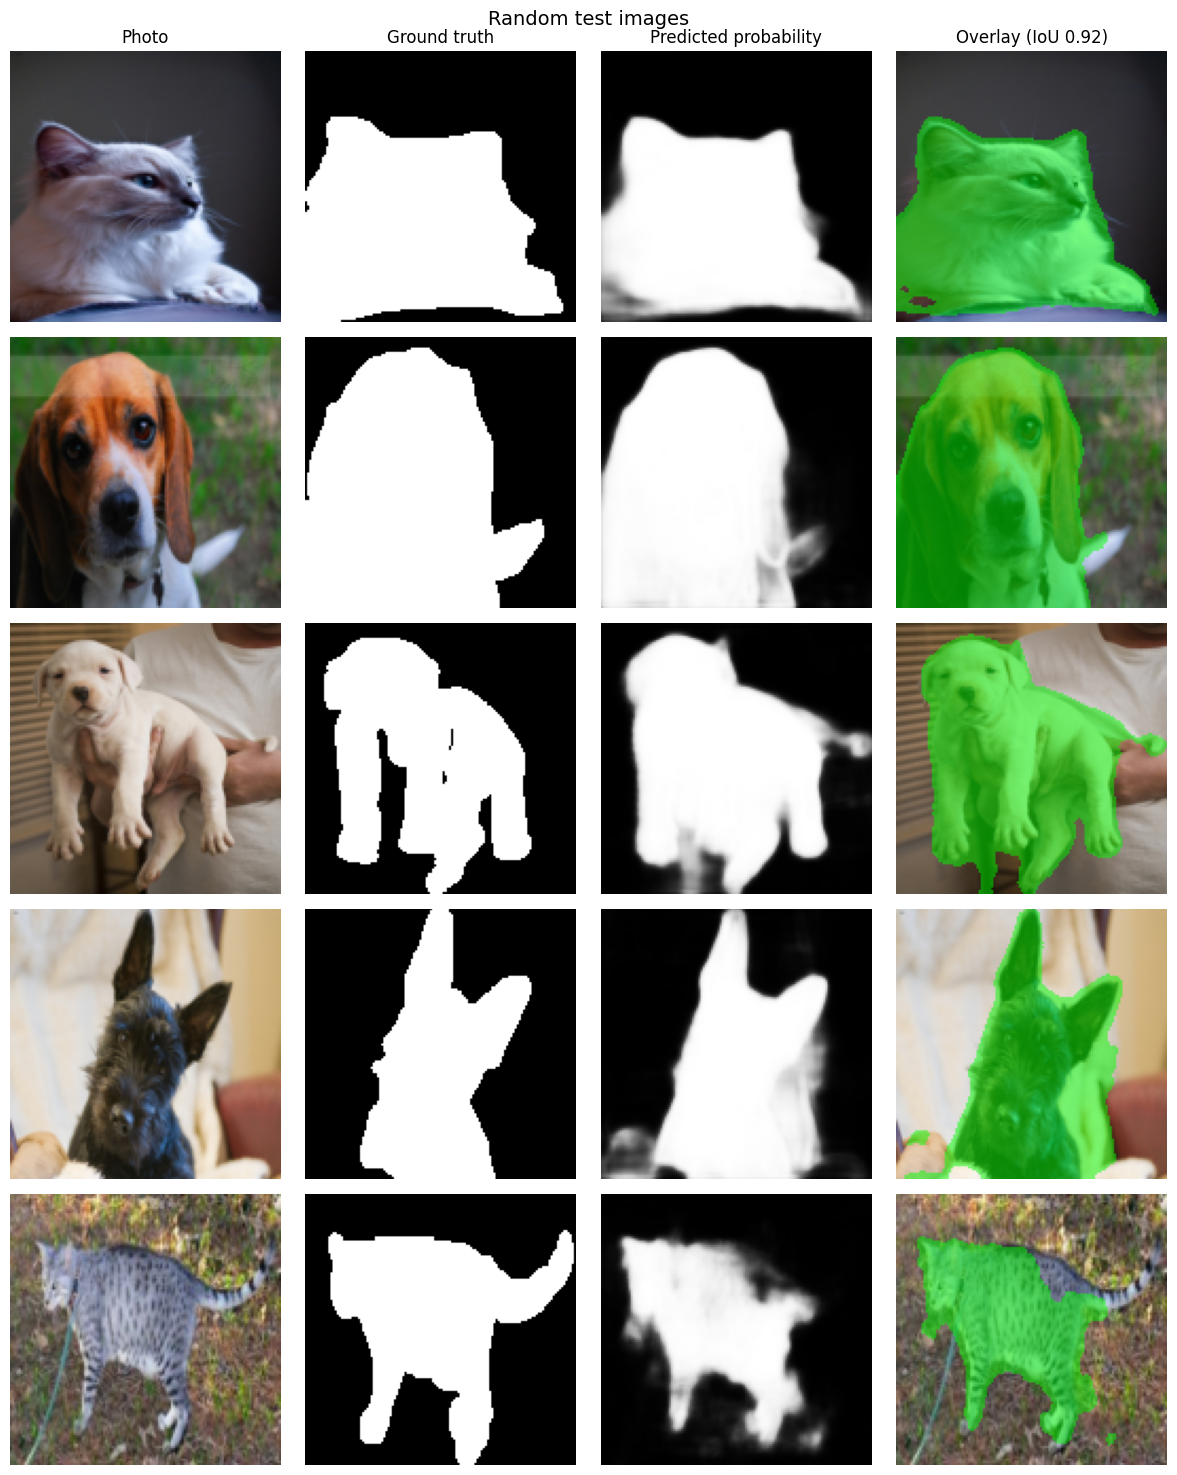

In [10]:
def denorm(x):
    m, s = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (x.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

def show_predictions(indices, title):
    fig, axes = plt.subplots(len(indices), 4, figsize=(12, 3 * len(indices)))
    for row, i in enumerate(indices):
        x, y = test_ds[i]
        with torch.no_grad():
            prob = torch.sigmoid(model(x.unsqueeze(0).to(device)))[0, 0].cpu()
        img = denorm(x)
        fg = (prob > 0.5).numpy()
        overlay = img.copy(); overlay[fg] = 0.5 * overlay[fg] + 0.5 * np.array([0, 1, 0])
        for col, (im, name) in enumerate([(img, "Photo"), (y[0], "Ground truth"),
                                          (prob, "Predicted probability"),
                                          (overlay, f"Overlay (IoU {test_ious[i]:.2f})")]):
            axes[row, col].imshow(im, cmap="gray" if col in (1, 2) else None)
            axes[row, col].axis("off")
            if row == 0: axes[row, col].set_title(name)
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

show_predictions(random.sample(range(len(test_ds)), 5), "Random test images")

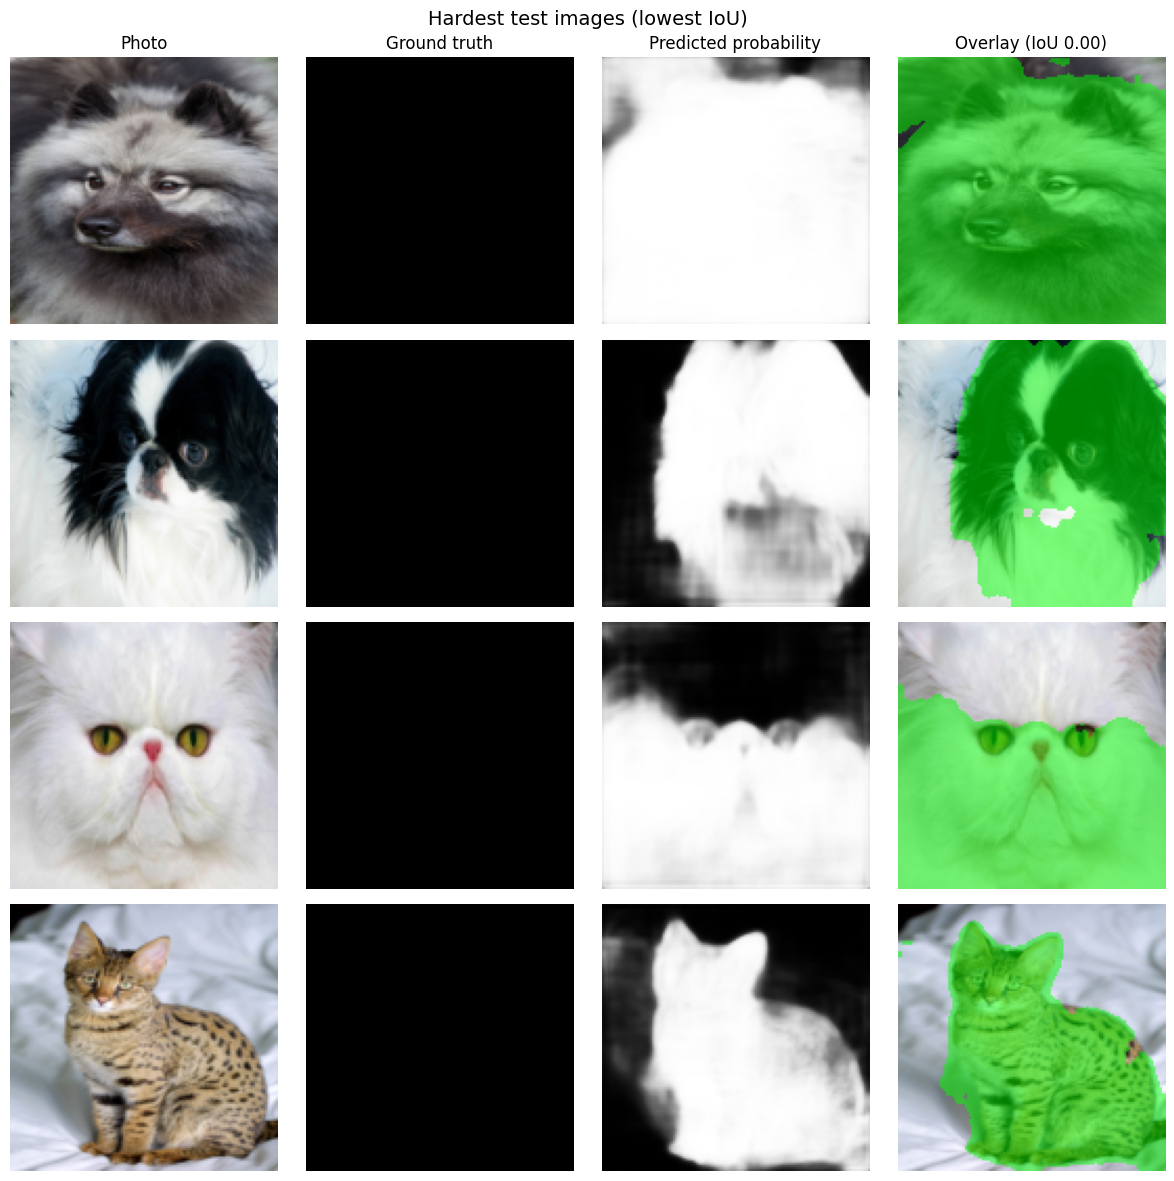

In [11]:
show_predictions(test_ious.argsort()[:4].tolist(), "Hardest test images (lowest IoU)")

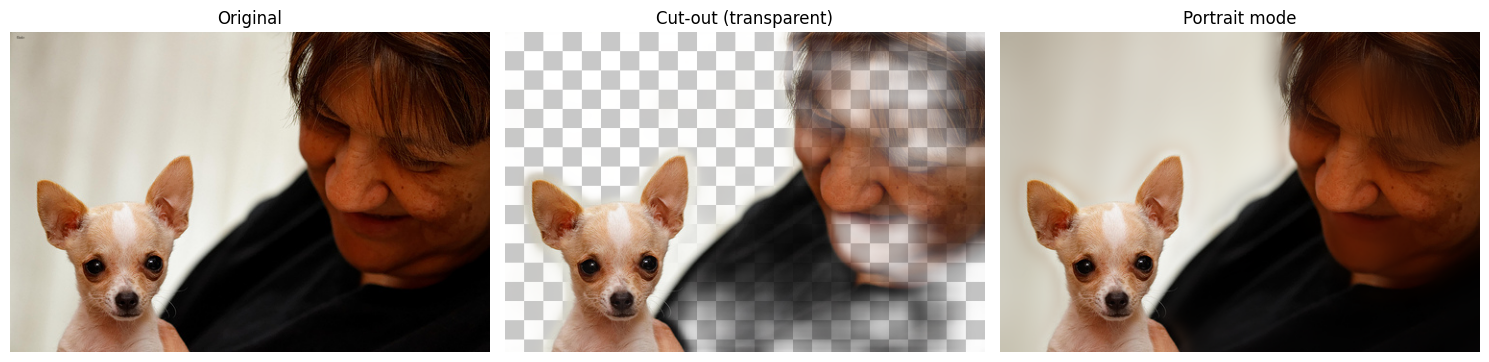

In [12]:
@torch.no_grad()
def remove_background(photo: Image.Image, blur_radius=12):
    photo = photo.convert("RGB")
    x = TF.normalize(TF.to_tensor(TF.resize(photo, [IMG_SIZE, IMG_SIZE])), MEAN, STD)
    prob = torch.sigmoid(model.eval()(x.unsqueeze(0).to(device)))
    prob = F.interpolate(prob, size=photo.size[::-1], mode="bilinear", align_corners=False)[0, 0].cpu()
    alpha = Image.fromarray((prob.numpy() * 255).astype(np.uint8))   # soft edges, not hard 0/1

    cutout = photo.copy(); cutout.putalpha(alpha)                     # transparent background
    portrait = Image.composite(photo, photo.filter(ImageFilter.GaussianBlur(blur_radius)), alpha)
    return cutout, portrait

photo, _ = test_raw[random.randrange(len(test_raw))]
cutout, portrait = remove_background(photo)
cutout.save("pet_cutout.png"); portrait.save("pet_portrait.jpg")

checker = Image.new("RGB", photo.size, (200, 200, 200))   # checkerboard to show transparency
for yy in range(0, photo.size[1], 20):
    for xx in range((yy // 20 % 2) * 20, photo.size[0], 40):
        checker.paste((255, 255, 255), (xx, yy, xx + 20, yy + 20))
checker.paste(cutout, (0, 0), cutout)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axes, [photo, checker, portrait], ["Original", "Cut-out (transparent)", "Portrait mode"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()